### 1. Import the necessary packages

In [120]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as sk

### 2. Load Dataset

Load the KNHANES 9th wave CSV and inspect shape, column names, and first rows.

In [121]:
df = pd.read_csv('../csv/KNHANES9.csv') 
print(df.shape)
print(df.columns.tolist())
print(df.head())


(6997, 798)
['mod_d', 'ID', 'ID_fam', 'year', 'region', 'town_t', 'apt_t', 'psu', 'sex', 'age', 'age_month', 'incm', 'ho_incm', 'incm5', 'ho_incm5', 'edu', 'occp', 'wt_hs', 'wt_itvex', 'wt_ntr', 'wt_pft', 'wt_tot', 'wt_pfnt', 'kstrata', 'cfam', 'genertn', 'allownc', 'house', 'live_t', 'ainc_unit1', 'ainc_1', 'ainc', 'marri_1', 'marri_2', 'fam_rela', 'tins', 'npins', 'ID_F', 'ID_M', 'D_1_1', 'D_2_1', 'D_2_wk', 'DI1_dg', 'DI1_ag', 'DI1_pr', 'DI1_pt', 'DI1_2', 'DI2_dg', 'DI2_ag', 'DI2_pr', 'DI2_pt', 'DI2_2', 'DE1_dg', 'DE1_ag', 'DE1_pr', 'DE1_pt', 'DE1_3', 'DE1_31', 'DE1_32', 'DE1_33', 'DE1_34', 'DE1_35', 'DE1_4', 'DN1_dg', 'DN1_pt', 'DI3_dg', 'DI3_ag', 'DI3_2', 'DI4_dg', 'DI5_dg', 'DI5_ag', 'DI6_dg', 'DI6_ag', 'DJ2_dg', 'DJ2_ag', 'DC01_dg', 'DC01', 'DC01_tp1', 'DC01_ag', 'DJ4_dg', 'DJ4_ag', 'DJ4_3', 'DL1_dg', 'DL1_ag', 'DJ8_dg', 'DJ8_ag', 'DM4_dg', 'DM4_ag', 'DM4_pt', 'M_2_yr', 'M_2_rs', 'M_2_et', 'mt_nontrt', 'M_HL_1', 'M_HL_2', 'M_HL_3', 'M_HL_4', 'M_HL_5', 'M_HL_6', 'M_HL_7', 'M_HL_8'

### 2.1 Feature Selection & Age Filtering

Select the 12 candidate columns and restrict to respondents aged ≥ 40, where clinically significant tooth loss is most prevalent.

| Column | Description |
|--------|-------------|
| `age` | Respondent age |
| `sex` | Sex (1 = male, 2 = female); used only to compute eGFR, then dropped |
| `ho_incm` | Household income quintile |
| `edu` | Education level |
| `BS1_1` | Subjective health status (1 = very good → 5 = very bad; reversed later) |
| `BD1` | Smoking status |
| `BM7` | Exercise frequency (reversed so higher = more active) |
| `BM14` | Alcohol consumption (binarised: 1 = drinker, 0 = non/ex-drinker) |
| `HE_HbA1c` | Glycated haemoglobin (%) |
| `HE_BMI` | Body mass index (kg/m²) |
| `HE_crea` | Serum creatinine — used to derive eGFR, then dropped |
| `O_TC` | Total tooth count (target variable) |


## Based on the research paper and the process we're about to do:
- Smoking and Drinking doesn't have a high correlation with tooth loss. Moreover, the variables that determine smoking and drinking that are necessary towards this research is quite faulty. 특히, 결측치가 너무 많다, 또한 관련성이 되게 낮다. 이 노트북을 만들기 전, 흡연과 음주 변수의 correlation을 확인해봤는데 이 2 특징이 모델에 좋은 피처를 두면 안된다고 생각함으로, 주요 특징을 바꿨다. 

- 새로운 피처들은: Chronic Kidney Disease (CKD)와 당뇨 Diabetes, 마지막으로는 BMI 
- 그러므로, 공변량은 흡연, 음주, etc.

In [122]:
raw_columns = ['age', 'sex', 'ho_incm', 'edu', 'BS1_1', 'BD1',
               'BM7', 'BM14', 'HE_HbA1c', 'HE_BMI', 'HE_crea', 'O_TC']

age_threshold = 40 
df_subset = df[raw_columns].copy()
df_subset = df_subset[df_subset['age'] >= age_threshold]
print(df_subset.shape)
print(df_subset.columns.tolist())

(4680, 12)
['age', 'sex', 'ho_incm', 'edu', 'BS1_1', 'BD1', 'BM7', 'BM14', 'HE_HbA1c', 'HE_BMI', 'HE_crea', 'O_TC']


## 3. Target Variable — Cleaning & Binary Label

Clean `O_TC` (total tooth count) and produce a binary classification target:

- **a.** The sentinel value `-1.80E+308` represents a missing/invalid entry in the raw KNHANES encoding.
- **b.** `pd.to_numeric(..., errors='coerce')` converts it and any other non-numeric values to `NaN`.
- **c.** Rows where `O_TC` is `NaN` are dropped; only records with a valid tooth count are kept.
- **d.** Binary label `O_TC_`: `1` if tooth count < 20 (functionally impaired), `0` otherwise.
- **e.** Class imbalance is assessed via the ratio of majority (0) to minority (1) class counts.


In [123]:
print(df_subset[pd.to_numeric(df_subset['O_TC'], errors='coerce').isna()]['O_TC'].unique())

df_subset['O_TC'] = pd.to_numeric(df_subset['O_TC'], errors='coerce')
df_subset['O_TC'] = df_subset['O_TC'].replace(-1.80e308, np.nan)   
before_drop = len(df_subset)
df_subset = df_subset.dropna(subset=['O_TC'])
print(f"Rows droppped (NaN O_TC): {before_drop - len(df_subset)}")

df_subset['O_TC_'] = (df_subset['O_TC'] < 20).astype(int)

label_counts    = df_subset['O_TC_'].value_counts()
label_0         = label_counts[0]
label_1         = label_counts[1]
imbalance_ratio = label_0 / label_1

print(f"Age filter: >= {age_threshold}")
print(f"Label 0 (≥20 teeth): {label_0}")
print(f"Label 1 (<20 teeth): {label_1}")
print(df_subset['O_TC'].value_counts(dropna=False).head(20))
print(f"Imbalance ratio: {imbalance_ratio:.2f}")

print(f"NaN count: {df_subset['O_TC'].isna().sum()}")

['-1.80E+308']
Rows droppped (NaN O_TC): 533
Age filter: >= 40
Label 0 (≥20 teeth): 3242
Label 1 (<20 teeth): 905
O_TC
28.0    911
27.0    451
26.0    353
24.0    220
25.0    208
29.0    196
32.0    183
23.0    182
0.0     179
30.0    135
22.0    119
21.0    115
20.0     93
31.0     76
19.0     71
16.0     59
17.0     54
18.0     53
15.0     41
12.0     39
Name: count, dtype: int64
Imbalance ratio: 3.58
NaN count: 0


## 4. Missing Value Audit & Invalid-Code Replacement

Survey responses use reserved codes (8, 9, 88, 99, 888, 999) for refusals and non-applicable items — these are **not** true values and must be replaced with `NaN` before modelling.

- **Survey columns** (`BS1_1`, `BD1`, `edu`, `ho_incm`, `BM7`, `BM14`): replace invalid codes with `NaN`.
- **Lab columns** (`HE_HbA1c`, `HE_BMI`, `HE_crea`): coerce to numeric and nullify sentinel magnitudes (≥ 1e10).
- Creatinine values ≤ 0 are physiologically impossible and are also nullified.


In [124]:
'''
invalid_codes = [88, 888, 999]
feature_cols  = ['age', 'sex', 'ho_incm', 'edu', 'BS1_1', 'BD1',
                 'BM7', 'BM14', 'HE_HbA1c', 'HE_BMI', 'HE_crea']

df_subset[feature_cols] = df_subset[feature_cols].replace(invalid_codes, np.nan)
df_subset[feature_cols] = df_subset[feature_cols].apply(pd.to_numeric, errors='coerce')
df_subset[feature_cols] = df_subset[feature_cols].where(df_subset[feature_cols].abs() < 1e10, np.nan)

print("NaN counts per column after cleaning:")
total = len(df_subset)
for col in feature_cols:
    count = df_subset[col].isna().sum()
    pct = (count/total) * 100 
    print(f"{col}: {count} | ({pct:.1f}%)")

'''
import numpy as np

invalid_codes = [8, 9, 88, 99, 888, 999]
survey_cols   = ['BS1_1', 'BD1', 'edu', 'ho_incm', 'BM7', 'BM14']
lab_cols      = ['HE_HbA1c', 'HE_BMI', 'HE_crea']

df_subset[survey_cols] = df_subset[survey_cols].replace(invalid_codes, np.nan)
df_subset[lab_cols]    = df_subset[lab_cols].apply(pd.to_numeric, errors='coerce')
df_subset[lab_cols]    = df_subset[lab_cols].where(df_subset[lab_cols].abs() < 1e10, np.nan)

# Creatinine must be positive
df_subset.loc[df_subset['HE_crea'] <= 0, 'HE_crea'] = np.nan

print("NaN counts per column after cleaning:")
total = len(df_subset)
for col in survey_cols:
    count = df_subset[col].isna().sum()
    pct = (count/total) * 100 
    print(f"{col}: {count} | ({pct:.1f}%)")
for col in lab_cols:
    count = df_subset[col].isna().sum()
    pct = (count/total) * 100 
    print(f"{col}: {count} | ({pct:.1f}%)")


NaN counts per column after cleaning:
BS1_1: 53 | (1.3%)
BD1: 52 | (1.3%)
edu: 0 | (0.0%)
ho_incm: 0 | (0.0%)
BM7: 53 | (1.3%)
BM14: 53 | (1.3%)
HE_HbA1c: 123 | (3.0%)
HE_BMI: 79 | (1.9%)
HE_crea: 123 | (3.0%)


### 4.1 Ordinal Remapping

Recode ordinal survey variables so that **higher values consistently indicate a worse health-related behaviour**, aligning all features for intuitive model interpretation.

| Column | Original coding | After remapping |
|--------|-----------------|-----------------|
| `BM7` | 1 = very active → 5 = sedentary | Reversed: `6 − BM7` (higher = more active → lower after reversal = healthier) |
| `BM14` | 1 = current drinker, 2/3 = non/ex | Binary: 1 = drinker, 0 = non/ex-drinker |
| `BS1_1` | 1 = very good → 4 = very bad | Reversed: `4 − BS1_1` (higher = better subjective health) |


In [125]:
df_subset[survey_cols] = df_subset[survey_cols].apply(pd.to_numeric, errors='coerce')
df_subset[survey_cols] = df_subset[survey_cols].replace(invalid_codes, np.nan)

df_subset['BM7']  = 6 - df_subset['BM7']
df_subset['BM14'] = df_subset['BM14'].map({1: 1, 2: 0, 3: 0})
df_subset['BS1_1'] = 4 - df_subset['BS1_1']

### 4.2 Derived Feature — eGFR (CKD-EPI 2021)

Replace raw serum creatinine with estimated Glomerular Filtration Rate (eGFR) using the **CKD-EPI 2021 creatinine equation**. eGFR is a more clinically interpretable measure of kidney function than creatinine alone and reduces the sex-dependence of the raw value.

`sex` and `HE_crea` are dropped after the derivation.


In [126]:
def calculate_egfr(row):
    scr = row['HE_crea']
    age = row['age']
    sex = row['sex']   # KNHANES: 1 = male, 2 = female

    if pd.isna(scr) or pd.isna(sex):
        return np.nan

    if sex == 2:   # female
        kappa, alpha, sex_factor = 0.7, -0.241, 1.012
    else:          # male
        kappa, alpha, sex_factor = 0.9, -0.302, 1.0

    ratio = scr / kappa
    return (142
            * (min(ratio, 1) ** alpha)
            * (max(ratio, 1) ** -1.200)
            * (0.9938 ** age)
            * sex_factor)

df_subset['eGFR'] = df_subset.apply(calculate_egfr, axis=1)
df_subset = df_subset.drop(columns=['HE_crea', 'sex'])

## 5. Train / Test Split & Median Imputation

Split the cleaned dataset (80 / 20, stratified on `O_TC_`) then apply **median imputation** on the training fold. The fitted imputer is applied to the test set without refitting, preventing data leakage.


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

feature_cols = ['age', 'ho_incm', 'edu', 'BS1_1', 'BD1',
                'BM7', 'BM14', 'HE_HbA1c', 'HE_BMI', 'eGFR']

X = df_subset[feature_cols].replace([np.inf, -np.inf], np.nan)
y = df_subset['O_TC_']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Total values imputed: {X_train.isna().sum().sum()}")
imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
X_test  = pd.DataFrame(imputer.transform(X_test),  columns=X_test.columns)


Total values imputed: 914


## 6. Standardisation

Scale features to zero mean and unit variance for distance- and gradient-based models.

- `X_train_scaled` / `X_test_scaled` — used for **Logistic Regression** and **SVM**.
- `X_train_tree` / `X_test_tree` — unscaled copies used for **Random Forest**, **XGBoost**, and **LightGBM**, which are scale-invariant.


In [128]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# For Logistic Regression and SVM — normalize all features
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# For RF, XGBoost, LightGBM — NO standardization needed
X_train_tree = X_train.copy()
X_test_tree  = X_test.copy()

## 7. Class Imbalance — SMOTE (ratio 1 : 1.5)

The minority class (`O_TC_ = 1`, tooth count < 20) is underrepresented by a factor of ~3.6×. SMOTE is applied **inside each CV fold via an `ImbPipeline`** to prevent leakage — synthetic samples from the training fold never contaminate the validation fold.


In [129]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

print("Class distribution before SMOTE:")
print("Before:", pd.Series(y_train).value_counts().to_dict())
print("(SMOTE will now be applied inside each CV fold via pipeline — no standalone resampling)")


Class distribution before SMOTE:
Before: {0: 2593, 1: 724}
(SMOTE will now be applied inside each CV fold via pipeline — no standalone resampling)


### Hyperparameter Tuning

**Method:** RandomizedSearchCV (faster than GridSearch for 5 models; 50 iterations per model, `scoring = 'roc_auc'`)

| Model                   | Key Hyperparameters                                                | Tuning Range                                     |
| :---------------------- | :----------------------------------------------------------------- | :----------------------------------------------- |
| **Random Forest**       | `n_estimators`, `max_depth`, `min_samples_leaf`                    | 100/300/500 · 5/10/15/None · 1/5/10              |
| **XGBoost**             | `n_estimators`, `max_depth`, `learning_rate`, `subsample`          | 100/300/500 · 3/5/7 · 0.01/0.1/0.3 · 0.7/0.8/1.0 |
| **LightGBM**            | `n_estimators`, `num_leaves`, `learning_rate`, `min_child_samples` | 100/300/500 · 15/31/63 · 0.01/0.1/0.3 · 5/10/20  |
| **Logistic Regression** | `C`, `penalty`                                                     | 0.01/0.1/1/10 · L1/L2                            |
| **SVM**                 | `C`, `kernel`, `gamma`                                             | 0.1/1/10 · rbf/linear · scale/auto               |

## 8. Hyperparameter Tuning — RandomizedSearchCV

**Method:** `RandomizedSearchCV` with 5-fold `StratifiedKFold`, 50 iterations per model, scored by `roc_auc`. SMOTE is embedded inside each fold pipeline to avoid leakage.

| Model | Key hyperparameters tuned |
|-------|--------------------------|
| **Random Forest** | `n_estimators`, `max_depth`, `min_samples_leaf` |
| **XGBoost** | `n_estimators`, `max_depth`, `learning_rate`, `subsample` |
| **LightGBM** | `n_estimators`, `num_leaves`, `learning_rate`, `min_child_samples` |
| **Logistic Regression** | `C`, `penalty` (L1 / L2 via SAGA solver) |


In [130]:
import sys
!{sys.executable} -m pip install xgboost


[notice] A new release of pip is available: 24.0 -> 26.1.1
[notice] To update, run: pip install --upgrade pip


### 8.1 Fit & Search


In [131]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

param_grids = {
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'model__n_estimators':     [100, 300, 500],
            'model__max_depth':        [5, 10, 15, None],
            'model__min_samples_leaf': [1, 5, 10]
        }
    },
    'XGBoost': {
        'model': XGBClassifier(random_state=42, eval_metric='logloss'),
        'params': {
            'model__n_estimators':  [100, 300, 500],
            'model__max_depth':     [3, 5, 7],
            'model__learning_rate': [0.01, 0.1, 0.3],
            'model__subsample':     [0.7, 0.8, 1.0]
        }
    },
    # extremely fast; instead of level wise growth its leaf wise growth (vertical); high speed but prone to OVERFITTING
    'LightGBM': {
        'model': LGBMClassifier(random_state=42),
        'params': {
            'model__n_estimators':      [100, 300, 500],
            'model__num_leaves':        [15, 31, 63],
            'model__learning_rate':     [0.01, 0.1, 0.3],
            'model__min_child_samples': [5, 10, 20]
        }
    },
    'Logistic Regression': {
        'model': LogisticRegression(random_state=42, max_iter=1000, solver='saga'),
        'params': {
            'model__C':       [0.01, 0.1, 1, 10],
            'model__penalty': ['l1', 'l2']
        }
    },
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

for name, config in param_grids.items():
    # SMOTE is inside the pipeline so it only sees training folds during CV (no leakage) -- this was because 
    # the AUC scores for all models were a bit too high (over 0.95) this assumes a leakage 
    # what does data leakage mean -> info from validation set "leaks" to the training process --> basically cheating
    # 
    pipeline = ImbPipeline([
        ('smote', SMOTE(sampling_strategy=1/1.5, random_state=42)),
        ('model', config['model'])
    ])
    #from here on is the testing of models 
    search = RandomizedSearchCV(
        estimator           = pipeline,
        param_distributions = config['params'],
        n_iter              = 50,
        cv                  = cv,
        scoring             = 'roc_auc',
        random_state        = 42,
        n_jobs              = -1
    )
    search.fit(X_train, y_train)  # original X_train — SMOTE applied inside each fold
    results[name] = {
        'best_params':   search.best_params_,
        'best_cv_score': search.best_score_
    }
    print(f"{name}: Best AUC = {search.best_score_:.4f} | Params: {search.best_params_}")

results_df = pd.DataFrame(
    {name: {'AUC': v['best_cv_score']} for name, v in results.items()}
).T.sort_values('AUC', ascending=False)
print(results_df)


Random Forest: Best AUC = 0.8300 | Params: {'model__n_estimators': 300, 'model__min_samples_leaf': 5, 'model__max_depth': 5}
XGBoost: Best AUC = 0.8361 | Params: {'model__subsample': 0.7, 'model__n_estimators': 500, 'model__max_depth': 3, 'model__learning_rate': 0.01}
[LightGBM] [Info] Number of positive: 1382, number of negative: 2074
[LightGBM] [Info] Number of positive: 1382, number of negative: 2074
[LightGBM] [Info] Number of positive: 1383, number of negative: 2075
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.009125 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.009096 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.009739 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can s

/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warni

Logistic Regression: Best AUC = 0.8267 | Params: {'model__penalty': 'l1', 'model__C': 0.1}
                          AUC
XGBoost              0.836115
LightGBM             0.833053
Random Forest        0.830037
Logistic Regression  0.826744


## 9. PyCaret Screening — Top 3 Models by AUC

Use PyCaret's `compare_models` as an automated second opinion across a broader algorithm pool. Fix class imbalance and normalise inside the setup so results are directly comparable to the manual tuning above. The top 3 models by cross-validated AUC are retained for visualisation.


In [135]:
from pycaret.classification import *

feature_cols = ['age', 'ho_incm', 'edu', 'BS1_1', 'BD1',
                'BM7', 'BM14', 'HE_HbA1c', 'HE_BMI', 'eGFR', 'O_TC_']

df_train = df_subset[feature_cols].copy()

clf = setup(
    data          = df_train,
    target        = 'O_TC_',
    fix_imbalance = True,
    normalize     = True,
    fold          = 5,
    fold_strategy = 'stratifiedkfold',
    session_id    = 42
)

best_models = compare_models(sort='AUC', n_select=3)

,Description,Value
0,Session id,42
1,Target,O_TC_
2,Target type,Binary
3,Original data shape,"(4147, 11)"
4,Transformed data shape,"(5783, 11)"
5,Transformed train set shape,"(4538, 11)"
6,Transformed test set shape,"(1245, 11)"
7,Numeric features,10
8,Rows with missing values,7.8%
9,Preprocess,True


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
ridge,Ridge Classifier,0.7378,0.8340,0.8104,0.4452,0.5745,0.4075,0.4458,0.0100
lda,Linear Discriminant Analysis,0.7378,0.8340,0.8104,0.4452,0.5745,0.4075,0.4458,0.0240
lr,Logistic Regression,0.7433,0.8337,0.7867,0.4505,0.5726,0.4083,0.4407,0.2640
ada,Ada Boost Classifier,0.7970,0.8322,0.5703,0.5338,0.5506,0.4199,0.4209,0.0460
gbc,Gradient Boosting Classifier,0.8081,0.8266,0.4912,0.5701,0.5271,0.4076,0.4098,0.1300
rf,Random Forest Classifier,0.8015,0.8138,0.4376,0.5623,0.4904,0.3697,0.3752,0.0960
nb,Naive Bayes,0.7340,0.8119,0.7599,0.4376,0.5551,0.3846,0.4146,0.0220
lightgbm,Light Gradient Boosting Machine,0.7977,0.8105,0.4344,0.5459,0.4827,0.3593,0.3635,0.3220
svm,SVM - Linear Kernel,0.7233,0.8094,0.7536,0.4265,0.5435,0.3671,0.3985,0.0140
et,Extra Trees Classifier,0.8029,0.8094,0.4202,0.5661,0.4805,0.3626,0.3697,0.0840


[LightGBM] [Info] Number of positive: 1815, number of negative: 1815
[LightGBM] [Info] Number of positive: 1815, number of negative: 1815
[LightGBM] [Info] Number of positive: 1815, number of negative: 1815
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000785 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000758 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2550
[LightGBM] [Info] Total Bins 2550
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002485 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2409
[LightGBM] [Info] Number of positive: 1815, number of negative: 1815
[LightGB

## 10. Visualisation — Confusion Matrix, Feature Importance, ROC Curve

Generate and save diagnostic plots for each of the 3 best PyCaret models. The AUC plot is skipped for models that lack `predict_proba` (e.g. LinearSVC).


In [144]:

from pycaret.classification import *

for model_name, model in zip(['LightGBM', 'XGBoost', 'RandomForest'], best_models):
    # Confusion Matrix
    plot_model(model, plot='confusion_matrix', save=True)

    # Feature Importance
    plot_model(model, plot='feature', save=True)

    # ROC Curve — skip if model has no predict_proba (e.g. LinearSVC)
    if hasattr(model, 'predict_proba'):
        plot_model(model, plot='auc', save=True)
    else:
        print(f"{model_name}: AUC plot skipped (no predict_proba)")


LightGBM: AUC plot skipped (no predict_proba)


### 10.1 ROC Curve Comparison

Display all three ROC curves in sequence for side-by-side AUC comparison.

LightGBM: AUC plot skipped (no predict_proba)


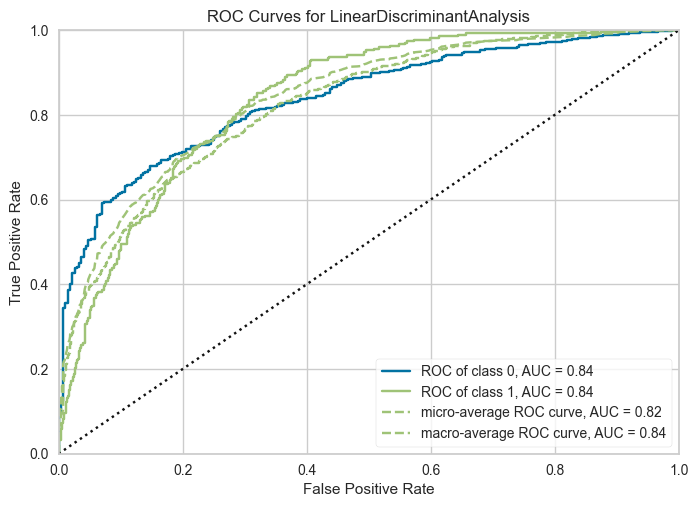

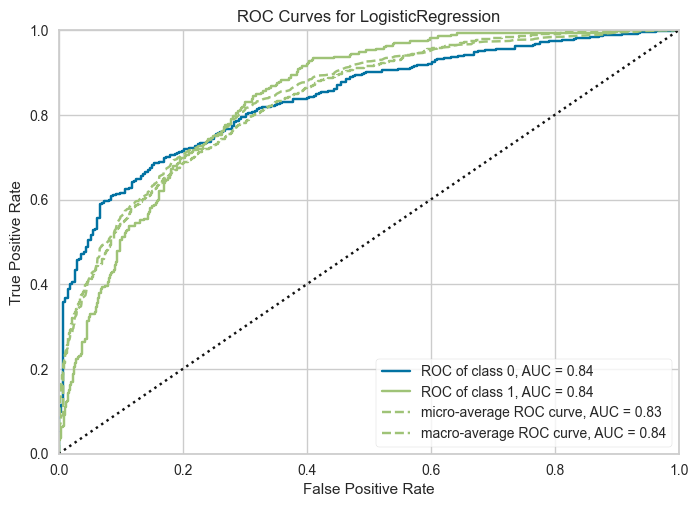

In [146]:
# All 3 ROC curves on the same plot for comparison

for model_name, model in zip(['LightGBM', 'XGBoost', 'RandomForest'], best_models):
    if hasattr(model, 'predict_proba'):
        plot_model(model, plot='auc')
    else:
        print(f"{model_name}: AUC plot skipped (no predict_proba)")